# DERCONNECT real data: building types, forecasting inputs and anomaly screening

Exploratory analysis of the five DERCONNECT meters (January–May 2026, ~2-second readings), covering three follow-ups to the team's EDA notebook:

- **Building types:** do buildings of the same type (per facilities management) behave alike?
- **Inputs for the anomaly-detection team:** data length, daily/weekly cycles, a clean calibration window, and simple forecast benchmarks.
- **Anomaly screening:** a first screen for real anomalies, compared with the anomaly types used in the synthetic dashboard data.

**How it runs.** Set `DERCONNECT_DATA_DIR` to the folder with the extracted monthly CSVs (for example `export DERCONNECT_DATA_DIR="$HOME/Downloads/Haojian_Data"`) and launch Jupyter from the repository. `tools/derconnect_prep.py` reads each raw CSV once (about 2 minutes) and caches 15-minute summaries in the Git-ignored `local-results/derconnect-building-types/` folder. Everything below works from those summaries, plus a list of recording gaps and repeated-value runs taken from the raw 2-second data. Hours with less than 90% of expected readings are treated as missing, never as zero.

| Meter | Building type |
|---|---|
| E2451 | Instructional |
| E3020 | Mixed |
| E3510, E7080, E7085 | Office |

This is screening, not ground truth: no candidate below is a confirmed fault. Federal holidays are marked; the UC academic calendar (quarter breaks) is **not** encoded and is a likely explanation for some late-March candidates.

In [1]:
from pathlib import Path
import os, sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools/derconnect_prep.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Launch Jupyter from the repository root or the notebooks directory.")
if str(ROOT / "tools") not in sys.path:
    sys.path.insert(0, str(ROOT / "tools"))
import derconnect_prep as prep

# Folder holding the extracted monthly CSVs (E2451/, E3020/, ...). Set it before launching Jupyter, e.g.
#   export DERCONNECT_DATA_DIR="$HOME/Downloads/Haojian_Data"
# No private path is stored in this notebook.
_data = os.environ.get("DERCONNECT_DATA_DIR", "")
DATA_DIR = Path(_data).expanduser() if _data else None
WORK_DIR = ROOT / "local-results" / "derconnect-building-types"     # Git-ignored: cache and exports stay local
CACHE_DIR = WORK_DIR / "cache"
EXPORT_DIR = WORK_DIR / "exports"
TZ = "America/Los_Angeles"

# Building type per facilities management (supplied by the instructor)
BUILDING_TYPE = {"E2451": "Instructional", "E3020": "Mixed", "E3510": "Office", "E7080": "Office", "E7085": "Office"}
METERS = list(BUILDING_TYPE)
TYPE_COLOR = {"Office": "#2a78d6", "Instructional": "#eb6834", "Mixed": "#1baf7a"}
METER_STYLE = {"E2451": "-", "E3020": "-", "E3510": "-", "E7080": "--", "E7085": ":"}
LABEL = {m: f"{m} ({t})" for m, t in BUILDING_TYPE.items()}
# US federal holidays in the period. The UC academic calendar (quarter breaks) is NOT encoded here.
HOLIDAYS = set(pd.to_datetime(["2026-01-01", "2026-01-19", "2026-02-16", "2026-05-25"]).date)

plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "legend.frameon": False,
})
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)

def style(m):
    return dict(color=TYPE_COLOR[BUILDING_TYPE[m]], linestyle=METER_STYLE[m], label=LABEL[m])

In [2]:
# One pass over the 25 raw CSVs (~2 min the first time); later runs reuse the local cache
if DATA_DIR is not None and DATA_DIR.is_dir():
    prep.prepare(DATA_DIR, CACHE_DIR)
elif any(CACHE_DIR.glob("agg15_*.csv")):
    print("DERCONNECT_DATA_DIR not set: using the existing local cache.")
else:
    raise RuntimeError("Set DERCONNECT_DATA_DIR to the folder with the extracted monthly CSVs, then run all cells.")
agg15, flats, gaps = prep.load(CACHE_DIR)
print(f"{len(agg15):,} fifteen-minute bins, {agg15.meter.nunique()} meters, "
      f"{agg15.bin_utc.min():%Y-%m-%d %H:%M} to {agg15.bin_utc.max():%Y-%m-%d %H:%M} UTC")

25/25 files cached
72,436 fifteen-minute bins, 5 meters, 2026-01-01 08:00 to 2026-06-01 06:45 UTC


In [3]:
# 15-minute coverage: 450 readings expected at the ~2 s cadence
agg15["coverage"] = agg15.P_total_count / 450
agg15["kW"] = (agg15.P_total_mean / 1000).where(agg15.coverage >= 0.9)
agg15["kW_max"] = (agg15.P_total_max / 1000).where(agg15.coverage >= 0.9)
agg15["t_local"] = agg15.bin_utc.dt.tz_convert(TZ)

# Hourly grid (every hour present, missing hours kept as NaN), count-weighted means
full_hours = pd.date_range(agg15.bin_utc.min().floor("h"), agg15.bin_utc.max().floor("h"), freq="h")
parts = []
for m in METERS:
    g = agg15[agg15.meter == m]
    hr = g.bin_utc.dt.floor("h")
    d = pd.DataFrame({
        "n": g.P_total_count.groupby(hr).sum(),
        "w": (g.P_total_mean * g.P_total_count).groupby(hr).sum(),
        "pmax": g.P_total_max.groupby(hr).max(),
    }).reindex(full_hours)
    d["meter"] = m
    parts.append(d)
hourly = pd.concat(parts).rename_axis("t_utc").reset_index()
hourly["n"] = hourly.n.fillna(0)
hourly["coverage"] = hourly.n / 1800
hourly["kW"] = (hourly.w / hourly.n / 1000).where(hourly.coverage >= 0.9)
hourly["peak_kW"] = (hourly.pmax / 1000).where(hourly.coverage >= 0.9)
hourly["t_local"] = hourly.t_utc.dt.tz_convert(TZ)
hourly["t_wall"] = hourly.t_local.dt.tz_localize(None)          # local wall-clock time
hourly["date"] = hourly.t_local.dt.date
hourly["hour"] = hourly.t_local.dt.hour
hourly["dow"] = hourly.t_local.dt.dayofweek
hourly["holiday"] = hourly.date.isin(HOLIDAYS)
hourly["weekend"] = hourly.dow >= 5
hourly["daytype"] = np.where(hourly.weekend | hourly.holiday, "Weekend/holiday", "Weekday")
hourly = hourly.drop(columns=["w", "pmax"])
H = {m: hourly[hourly.meter == m].set_index("t_wall") for m in METERS}   # per-meter views
print(f"{len(full_hours):,} hours per meter; eligible (>=90% coverage) hours:",
      hourly.groupby("meter").kW.count().to_dict())

3,623 hours per meter; eligible (>=90% coverage) hours: {'E2451': 3612, 'E3020': 3616, 'E3510': 3616, 'E7080': 3616, 'E7085': 3616}


## Can the three phases be added into one building total?

The earlier EDA kept phases A, B and C separate because summing them was not verified. Integrating A+B+C power over the five months and comparing it with the meter's own cumulative energy register (`Active_Energy_in_Quadrant_I`) checks this directly.

In [4]:
rows = []
for m in METERS:
    g = agg15[agg15.meter == m].sort_values("bin_utc")
    counter = g["Active_Energy_in_Quadrant_I_last"].dropna()
    integrated = (g.P_total_mean / 1000 * 0.25 * g.P_total_count / 450).sum()   # kWh from A+B+C power
    rows.append({"meter": m, "type": BUILDING_TYPE[m],
                 "counter_increase_kWh": counter.iloc[-1] - counter.iloc[0],
                 "integrated_A+B+C_kWh": integrated,
                 "ratio": (counter.iloc[-1] - counter.iloc[0]) / integrated,
                 "counter_decreases": int((counter.diff() < 0).sum()),
                 "export_kWh_QII+QIII": (g["Active_Energy_in_Quadrant_II_last"].iloc[-1] - g["Active_Energy_in_Quadrant_II_last"].iloc[0])
                                        + (g["Active_Energy_in_Quadrant_III_last"].iloc[-1] - g["Active_Energy_in_Quadrant_III_last"].iloc[0])})
phase_check = pd.DataFrame(rows).set_index("meter")
shown = phase_check.copy()
for c, fmt in {"counter_increase_kWh": "{:,.0f}", "integrated_A+B+C_kWh": "{:,.0f}", "ratio": "{:.4f}", "export_kWh_QII+QIII": "{:.3f}"}.items():
    shown[c] = shown[c].map(fmt.format)
display(shown)

,type,counter_increase_kWh,integrated_A+B+C_kWh,ratio,counter_decreases,export_kWh_QII+QIII
meter,,,,,,
E2451,Instructional,"289,582","289,343",1.0008,0,0.000
E3020,Mixed,"342,508","342,302",1.0006,0,0.000
E3510,Office,"410,628","410,352",1.0007,0,0.000
E7080,Office,"391,599","391,358",1.0006,0,0.000
E7085,Office,"226,395","226,240",1.0007,0,0.000


**Finding:** at every meter, the energy computed from A+B+C power matches the meter's cumulative energy register to within 0.1% (ratio 1.0006–1.0008; the tiny excess is the short recording gaps, which add to the register but not to the integral). The register never decreases, and the export registers (Quadrants II/III) stay at ~0, so no meter feeds power back, for example from solar.

**So A+B+C is the building's total active power**, and this notebook uses it as "load (kW)" from here on. This also unblocks building-level kW and kWh in the dashboard.

## Building-type comparison

Each building's typical behaviour, measured on hourly A+B+C load. The table's terms:

- **Base:** the 5th percentile of hourly load (the always-on load).
- **Weekend/weekday:** mean weekend-and-holiday load ÷ mean weekday load.
- **Night/workday:** mean 00:00–05:00 load ÷ mean weekday 10:00–16:00 load.
- **Load factor:** mean load ÷ the highest 15-minute load.

In [5]:
rows = []
for m in METERS:
    d = H[m]
    y = d.kW
    wk = d[d.daytype == "Weekday"]
    we = d[d.daytype == "Weekend/holiday"]
    night = d[d.hour.between(0, 4)].kW
    work = wk[wk.hour.between(10, 15)].kW
    prof = wk.groupby("hour").kW.mean()
    g15 = agg15[agg15.meter == m]
    rows.append({
        "meter": m, "type": BUILDING_TYPE[m],
        "mean_kW": y.mean(),
        "base_kW (p5)": y.quantile(0.05),
        "p95_kW": y.quantile(0.95),
        "max_15min_kW": g15.kW.max(),
        "daily_kWh": d.groupby("date").kW.sum(min_count=20).mean(),
        "weekend/weekday": we.kW.mean() / wk.kW.mean(),
        "night/workday": night.mean() / work.mean(),
        "base/peak (p5/p95)": y.quantile(0.05) / y.quantile(0.95),
        "load_factor": y.mean() / g15.kW.max(),
        "weekday_peak_hour": int(prof.idxmax()),
        "weekday_min_hour": int(prof.idxmin()),
    })
type_table = pd.DataFrame(rows).set_index("meter")
display(type_table.round(2))

,type,mean_kW,base_kW (p5),p95_kW,max_15min_kW,daily_kWh,weekend/weekday,night/workday,base/peak (p5/p95),load_factor,weekday_peak_hour,weekday_min_hour
meter,,,,,,,,,,,,
E2451,Instructional,79.95,39.17,121.73,134.25,1912.45,0.63,0.43,0.32,0.60,12,0
E3020,Mixed,94.52,76.78,113.95,135.46,2263.51,0.94,0.76,0.67,0.70,12,1
E3510,Office,113.29,74.10,167.01,190.30,2713.04,0.83,0.49,0.44,0.60,12,0
E7080,Office,108.07,85.92,136.98,174.92,2588.03,0.86,0.82,0.63,0.62,10,5
E7085,Office,62.47,46.68,81.57,99.40,1495.95,0.84,0.76,0.57,0.63,18,4


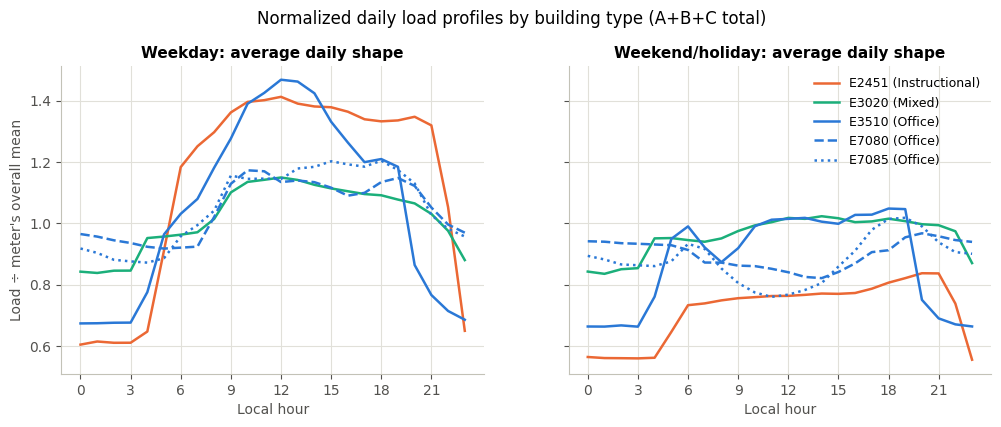

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, daytype in zip(axes, ["Weekday", "Weekend/holiday"]):
    for m in METERS:
        d = H[m]
        prof = d[d.daytype == daytype].groupby("hour").kW.mean() / d.kW.mean()
        ax.plot(prof.index, prof.values, **style(m))
    ax.set_title(f"{daytype}: average daily shape")
    ax.set_xlabel("Local hour")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Load ÷ meter's overall mean")
axes[1].legend(loc="upper right", fontsize=9)
fig.suptitle("Normalized daily load profiles by building type (A+B+C total)", y=1.02, fontsize=12)
plt.show()

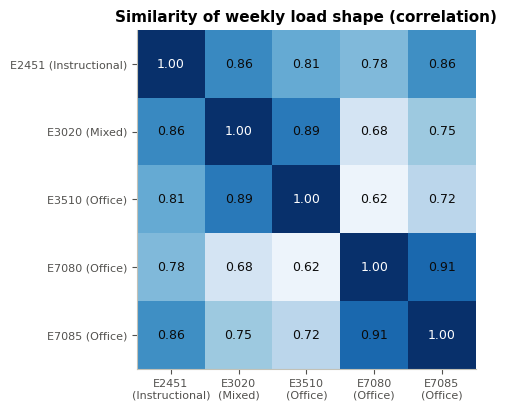

,E2451 (Instructional),E3020 (Mixed),E3510 (Office),E7080 (Office),E7085 (Office)
E2451 (Instructional),1.00,0.86,0.81,0.78,0.86
E3020 (Mixed),0.86,1.00,0.89,0.68,0.75
E3510 (Office),0.81,0.89,1.00,0.62,0.72
E7080 (Office),0.78,0.68,0.62,1.00,0.92
E7085 (Office),0.86,0.75,0.72,0.92,1.00


Office-office shape correlation: mean 0.752 (range 0.624-0.915)
Office-other  shape correlation: mean 0.794 (range 0.675-0.888)
Instructional-Mixed correlation: 0.864


In [7]:
# Hour-of-week shape (168 values, weekdays & weekends, holidays excluded) normalized by each meter's mean
how = {}
for m in METERS:
    d = H[m][~H[m].holiday]
    how[m] = d.groupby(["dow", "hour"]).kW.mean() / d.kW.mean()
how = pd.DataFrame(how)
corr = how.corr()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(corr.values, cmap="Blues", vmin=corr.values.min() - 0.02, vmax=1)
ax.set_xticks(range(5), [LABEL[m].replace(" (", "\n(") for m in METERS], fontsize=8)
ax.set_yticks(range(5), [LABEL[m] for m in METERS], fontsize=8)
ax.grid(False)
for i in range(5):
    for j in range(5):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.93 else "#0b0b0b")
ax.set_title("Similarity of weekly load shape (correlation)")
plt.show()

display(corr.round(3).rename(index=LABEL, columns=LABEL))
offices = [m for m in METERS if BUILDING_TYPE[m] == "Office"]
others = [m for m in METERS if m not in offices]
office_pairs = [corr.loc[a, b] for i, a in enumerate(offices) for b in offices[i + 1:]]
cross_pairs = [corr.loc[a, b] for a in offices for b in others]
print(f"Office-office shape correlation: mean {np.mean(office_pairs):.3f} (range {min(office_pairs):.3f}-{max(office_pairs):.3f})")
print(f"Office-other  shape correlation: mean {np.mean(cross_pairs):.3f} (range {min(cross_pairs):.3f}-{max(cross_pairs):.3f})")
print(f"Instructional-Mixed correlation: {corr.loc['E2451', 'E3020']:.3f}")

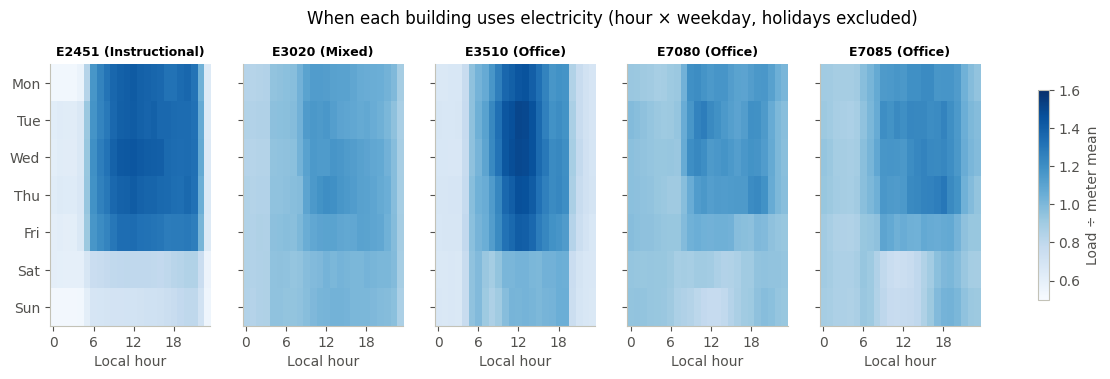

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharey=True)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for ax, m in zip(axes, METERS):
    mat = how[m].unstack("hour").reindex(range(7))
    im = ax.imshow(mat.values, aspect="auto", cmap="Blues", vmin=0.5, vmax=1.6)
    ax.set_title(LABEL[m], fontsize=9)
    ax.set_xticks([0, 6, 12, 18], ["0", "6", "12", "18"])
    ax.set_yticks(range(7), days)
    ax.set_xlabel("Local hour")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="Load ÷ meter mean")
fig.suptitle("When each building uses electricity (hour × weekday, holidays excluded)", y=1.04, fontsize=12)
plt.show()

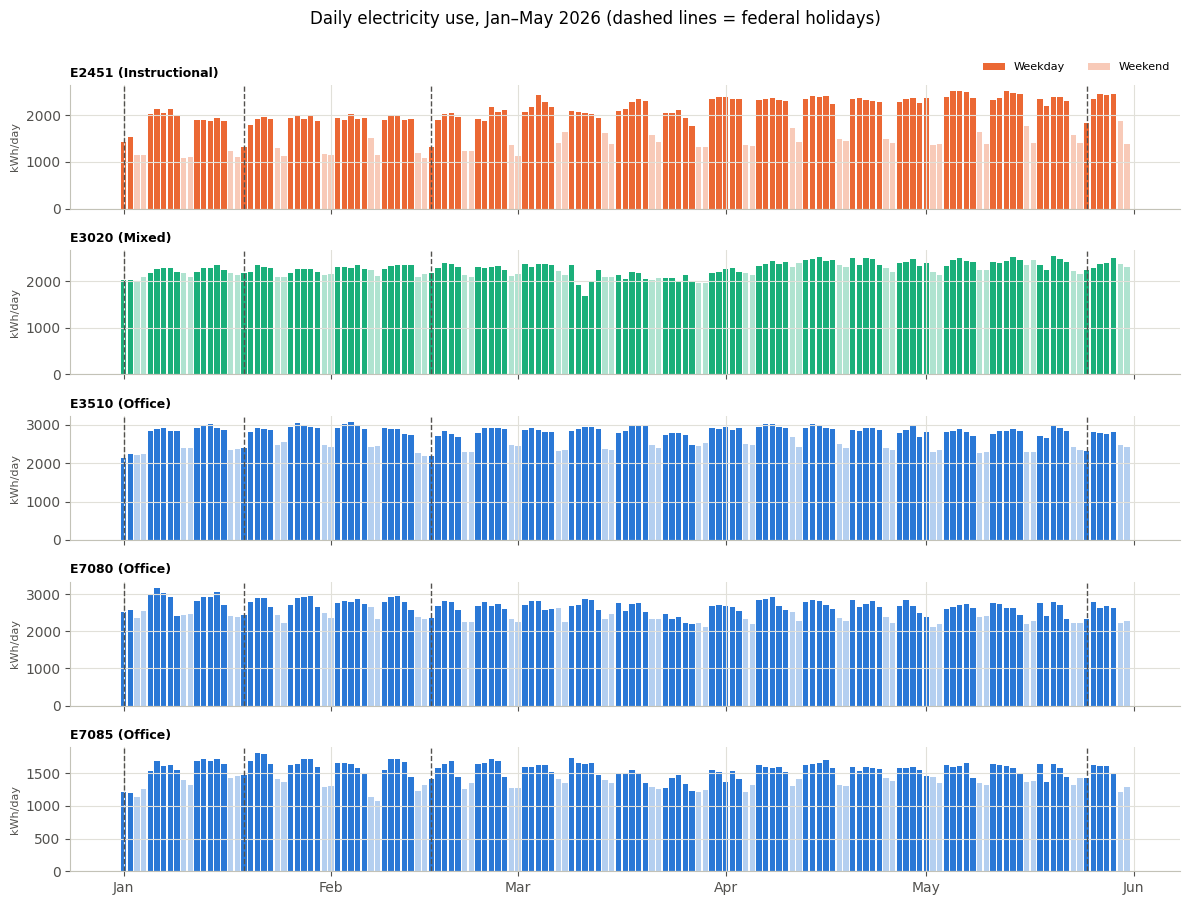

month,2026-01,2026-02,2026-03,2026-04,2026-05
mean kW relative to January,,,,,
E2451,1.0,1.05,1.16,1.26,1.26
E3020,1.0,1.03,0.97,1.08,1.08
E3510,1.0,1.00,1.01,1.03,0.98
E7080,1.0,0.97,0.94,0.97,0.93
E7085,1.0,0.98,0.95,0.98,0.97


In [9]:
fig, axes = plt.subplots(5, 1, figsize=(12, 9), sharex=True)
for ax, m in zip(axes, METERS):
    d = H[m].groupby("date").agg(kWh=("kW", lambda s: s.sum(min_count=20)), weekend=("weekend", "first"))
    d.index = pd.to_datetime(d.index)
    ax.bar(d.index[~d.weekend], d.kWh[~d.weekend], width=0.8, color=TYPE_COLOR[BUILDING_TYPE[m]], label="Weekday")
    ax.bar(d.index[d.weekend], d.kWh[d.weekend], width=0.8, color=TYPE_COLOR[BUILDING_TYPE[m]], alpha=0.35, label="Weekend")
    for h in HOLIDAYS:
        ax.axvline(pd.Timestamp(h), color="#52514e", lw=1, ls="--")
    ax.set_ylabel("kWh/day", fontsize=8)
    ax.set_title(LABEL[m], loc="left", fontsize=9)
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.02), fontsize=8, ncol=2)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.suptitle("Daily electricity use, Jan–May 2026 (dashed lines = federal holidays)", y=1.0, fontsize=12)
fig.tight_layout()
plt.show()

monthly = hourly.assign(month=hourly.t_local.dt.strftime("%Y-%m")).groupby(["meter", "month"]).kW.mean().unstack()
display((monthly.div(monthly.iloc[:, 0], axis=0)).round(2).rename_axis("mean kW relative to January"))

### Findings

**The buildings differ much more by individual behaviour than by type.**

- **E2451 (Instructional)** has the strongest rhythm. It uses less than half its daytime load at night (night/workday 0.43) and about a third less at weekends (0.63), and has the widest base-to-peak swing (0.32). It is also the only meter with a clear seasonal rise: monthly mean load is +16% in March and +26% in April–May compared with January.
- **E3020 (Mixed)** is the flattest: weekends are 94% of weekdays and nights 76% of the workday. It behaves like a building with large always-on equipment.
- **The three offices don't form one group.**
  - **E3510** has a strong office-hours cycle (night/workday 0.49; hour of day alone explains 78% of its variation).
  - **E7080 and E7085** carry a high base load (night/workday 0.82 and 0.76) with weak daily cycles. E7080 peaks around 10:00 and E7085 around 18:00.
- **Shape similarity confirms this.** The average correlation of weekly load shapes is 0.75 between offices, compared with 0.79 between offices and non-offices.
  - E7080 and E7085 form a close pair (0.92).
  - E3510 looks more like the Mixed building E3020 (0.89) than like the other offices (0.62–0.72).
- **Calendar effects are visible everywhere.** MLK Day, Presidents' Day and Memorial Day show as weekend-like days, most strongly at E3510 and E2451.
- **Implication for the dashboard and models:** don't assume a shared "office baseline" from the facilities label alone. Use per-meter baselines, or group meters by observed behaviour: {E7080, E7085}, {E3510, E3020} and E2451 on its own. Show the building type as context, not as the grouping key.

## Inputs for the anomaly-detection team

The repo's detectors (seasonal naive, rolling median/MAD and Chronos-2) are forecast-based. This section answers four questions:

1. How much usable data is there?
2. How strong are the daily and weekly cycles?
3. Which period could serve as a clean calibration window?
4. How accurate are simple baseline forecasts on this data?

All forecasts here are causal: they only use earlier hours, matched on local wall-clock time so daylight saving (March 8) doesn't shift them.

In [10]:
rows = []
for m in METERS:
    d = H[m]
    g15 = agg15[agg15.meter == m]
    gm = gaps[gaps.meter == m]
    missing = d.kW.isna()
    run_id = (missing != missing.shift()).cumsum()
    runs = missing.groupby(run_id).agg(["first", "size"])
    longest = runs[runs["first"]]["size"].max() if missing.any() else 0
    rows.append({"meter": m, "hours": len(d), "eligible_hours": int(d.kW.notna().sum()),
                 "eligible_%": 100 * d.kW.notna().mean(),
                 "eligible_15min_bins": int(g15.kW.notna().sum()),
                 "recording_gaps_>30s": len(gm), "longest_gap_min": gm.seconds.max() / 60 if len(gm) else 0,
                 "longest_missing_hour_run": int(longest)})
display(pd.DataFrame(rows).set_index("meter").round(1))

,hours,eligible_hours,eligible_%,eligible_15min_bins,recording_gaps_>30s,longest_gap_min,longest_missing_hour_run
meter,,,,,,,
E2451,3623,3612,99.7,14464,10,220.1,4
E3020,3623,3616,99.8,14479,9,21.2,2
E3510,3623,3616,99.8,14479,9,21.3,2
E7080,3623,3616,99.8,14479,10,21.2,2
E7085,3623,3616,99.8,14479,10,21.3,2


,type,acf_lag24,acf_lag168,R2_hour_of_day,R2_hour_of_week,R2_hour_of_week_by_month
meter,,,,,,
E2451,Instructional,0.73,0.92,0.47,0.84,0.94
E3020,Mixed,0.80,0.77,0.55,0.64,0.81
E3510,Office,0.89,0.94,0.78,0.93,0.94
E7080,Office,0.51,0.67,0.16,0.60,0.73
E7085,Office,0.62,0.78,0.26,0.69,0.77


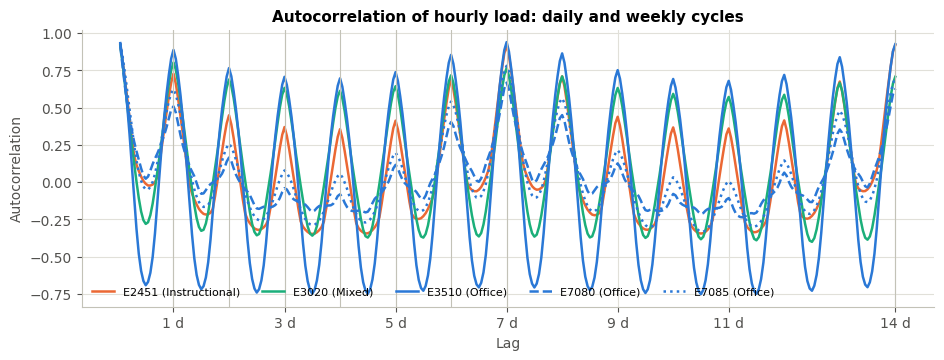

In [11]:
rows = []
acf = {}
for m in METERS:
    y = H[m].kW
    acf[m] = [y.autocorr(l) for l in range(1, 337)]
    d = H[m].dropna(subset=["kW"])
    var = d.kW.var()
    r2_hod = 1 - (d.kW - d.groupby("hour").kW.transform("mean")).var() / var
    r2_how = 1 - (d.kW - d.groupby(["dow", "hour"]).kW.transform("mean")).var() / var
    r2_howm = 1 - (d.kW - d.groupby([d.t_local.dt.month, "dow", "hour"]).kW.transform("mean")).var() / var
    rows.append({"meter": m, "type": BUILDING_TYPE[m], "acf_lag24": y.autocorr(24), "acf_lag168": y.autocorr(168),
                 "R2_hour_of_day": r2_hod, "R2_hour_of_week": r2_how, "R2_hour_of_week_by_month": r2_howm})
cycles = pd.DataFrame(rows).set_index("meter")
display(cycles.round(3))

fig, ax = plt.subplots(figsize=(11, 3.6))
for m in METERS:
    ax.plot(range(1, 337), acf[m], **style(m))
for lag in (24, 48, 72, 96, 120, 144, 168, 336):
    ax.axvline(lag, color="#c3c2b7", lw=0.8)
ax.set_xticks([24, 72, 120, 168, 216, 264, 336], ["1 d", "3 d", "5 d", "7 d", "9 d", "11 d", "14 d"])
ax.set_ylabel("Autocorrelation")
ax.set_xlabel("Lag")
ax.set_title("Autocorrelation of hourly load: daily and weekly cycles")
ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.show()

In [12]:
hourly["week"] = hourly.t_wall.dt.to_period("W-SUN").dt.start_time
weekly = hourly.groupby(["week", "meter"]).coverage.mean().unstack()
hol_weeks = set(hourly[hourly.holiday].week)
weekly["holiday_week"] = weekly.index.isin(hol_weeks)
weekly["min_coverage_all_meters"] = weekly[METERS].min(axis=1)

full = weekly[weekly[METERS].notna().all(axis=1)]
full = full[full.index >= pd.Timestamp("2026-01-05")]    # first full Monday week
cands = []
for i in range(len(full) - 3):
    w = full.iloc[i:i + 4]
    if (w.index[-1] - w.index[0]).days != 21:
        continue
    cands.append({"start": w.index[0].date(), "end": (w.index[-1] + pd.Timedelta(days=6)).date(),
                  "min_week_coverage": w.min_coverage_all_meters.min(), "holiday_weeks": int(w.holiday_week.sum())})
cands = pd.DataFrame(cands)
best = cands[(cands.holiday_weeks == 0) & (cands.min_week_coverage >= 0.99)].sort_values("start").head(6)
print("Weekly coverage (share of expected readings):")
display(weekly.round(4))
print("Candidate 4-week calibration windows (no federal-holiday week, >= 99% coverage at every meter):")
display(best.reset_index(drop=True).round(4))

Weekly coverage (share of expected readings):


meter,E2451,E3020,E3510,E7080,E7085,holiday_week,min_coverage_all_meters
week,,,,,,,
2025-12-29,1.00,1.0,1.0,1.0,1.0,True,1.00
2026-01-05,1.00,1.0,1.0,1.0,1.0,False,1.00
2026-01-12,1.00,1.0,1.0,1.0,1.0,False,1.00
2026-01-19,1.00,1.0,1.0,1.0,1.0,True,1.00
2026-01-26,1.00,1.0,1.0,1.0,1.0,False,1.00
2026-02-02,1.00,1.0,1.0,1.0,1.0,False,1.00
2026-02-09,1.00,1.0,1.0,1.0,1.0,False,1.00
2026-02-16,1.00,1.0,1.0,1.0,1.0,True,1.00
2026-02-23,0.98,1.0,1.0,1.0,1.0,False,0.98


Candidate 4-week calibration windows (no federal-holiday week, >= 99% coverage at every meter):


,start,end,min_week_coverage,holiday_weeks
0,2026-03-02,2026-03-29,1.0,0
1,2026-03-09,2026-04-05,1.0,0
2,2026-03-16,2026-04-12,1.0,0
3,2026-03-23,2026-04-19,1.0,0
4,2026-03-30,2026-04-26,1.0,0
5,2026-04-06,2026-05-03,1.0,0


meter,E2451,E3020,E3510,E7080,E7085
"MAE as % of mean load (Feb–May, hourly)",,,,,
"Hour-of-week median, last 4 weeks",7.8,5.8,4.6,7.0,7.3
"Rolling median, last 256 h (repo MedianMAD)",33.1,9.6,23.6,11.1,13.2
Seasonal naive (1 day),15.8,5.5,7.5,10.3,10.1
Seasonal naive (1 week),8.6,6.0,5.2,8.5,7.8


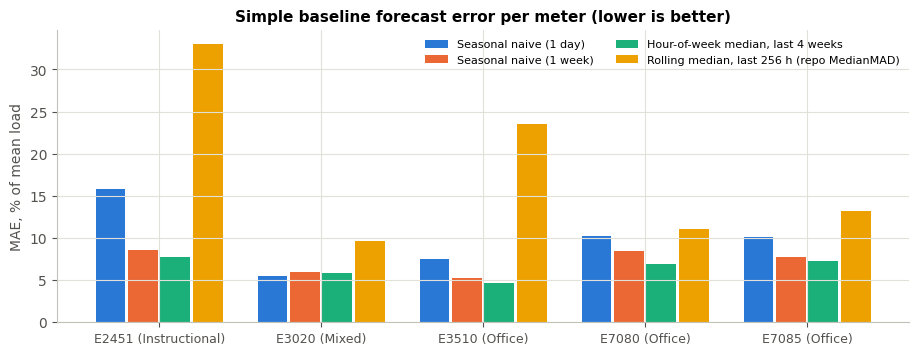

In [13]:
def lagged(series_wall, days):
    """Value at the same local wall-clock hour `days` earlier."""
    return series_wall.reindex(series_wall.index - pd.Timedelta(days=days)).to_numpy()

results, fc_store = [], {}
for m in METERS:
    y = H[m].kW
    f = pd.DataFrame(index=y.index)
    f["actual"] = y
    f["Seasonal naive (1 day)"] = lagged(y, 1)
    f["Seasonal naive (1 week)"] = lagged(y, 7)
    lags = np.column_stack([lagged(y, 7 * k) for k in range(1, 5)])
    med = np.nanmedian(lags, axis=1)
    med[np.isfinite(lags).sum(axis=1) < 2] = np.nan        # need at least two earlier weeks
    f["Hour-of-week median, last 4 weeks"] = med
    f["Rolling median, last 256 h (repo MedianMAD)"] = y.shift(1).rolling(256, min_periods=128).median().to_numpy()
    fc_store[m] = f
    ev = f[f.index >= pd.Timestamp("2026-02-01")].dropna()
    for col in f.columns[1:]:
        err = ev[col] - ev.actual
        results.append({"meter": m, "method": col, "MAE_kW": err.abs().mean(),
                        "MAE_%_of_mean": 100 * err.abs().mean() / ev.actual.mean(),
                        "sMAPE_%": 100 * (2 * err.abs() / (ev[col].abs() + ev.actual.abs())).mean(),
                        "n_hours": len(ev)})
bench = pd.DataFrame(results)
display(bench.pivot(index="method", columns="meter", values="MAE_%_of_mean").round(1)
        .rename_axis("MAE as % of mean load (Feb–May, hourly)"))

methods = list(fc_store[METERS[0]].columns[1:])
fig, ax = plt.subplots(figsize=(11, 3.8))
width = 0.8 / len(methods)
cols = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
for i, meth in enumerate(methods):
    vals = bench[bench.method == meth].set_index("meter").loc[METERS, "MAE_%_of_mean"]
    ax.bar(np.arange(5) + (i - 1.5) * width, vals, width * 0.92, color=cols[i], label=meth)
ax.set_xticks(range(5), [LABEL[m] for m in METERS], fontsize=9)
ax.set_ylabel("MAE, % of mean load")
ax.set_title("Simple baseline forecast error per meter (lower is better)")
ax.legend(fontsize=8, ncol=2)
plt.show()

In [14]:
EXPORT_DIR.mkdir(exist_ok=True)
out = hourly[["meter", "t_utc", "t_local", "kW", "peak_kW", "coverage", "daytype", "holiday"]].copy()
out["building_type"] = out.meter.map(BUILDING_TYPE)
out.to_csv(EXPORT_DIR / "hourly_total_kW.csv", index=False)
q15 = agg15[["meter", "bin_utc", "kW", "kW_max", "coverage"]]
q15.to_csv(EXPORT_DIR / "fifteen_min_total_kW.csv", index=False)
rel = EXPORT_DIR.relative_to(ROOT)
print(f"Wrote {rel/'hourly_total_kW.csv'} ({len(out):,} rows) and {rel/'fifteen_min_total_kW.csv'} ({len(q15):,} rows) (Git-ignored)")

Wrote local-results/derconnect-building-types/exports/hourly_total_kW.csv (18,115 rows) and local-results/derconnect-building-types/exports/fifteen_min_total_kW.csv (72,436 rows) (Git-ignored)


### Findings

- **Data length:**
  - **Volume:** each meter has 3,623 hours (about 14,480 fifteen-minute bins), and 99.7–99.8% of hours are usable.
  - **Gaps:** the longest missing stretch is 2 hours at four meters and 4 hours at E2451 (a 3.7-hour outage on Feb 24).
  - **Enough for the repo's models:** this is ample for the repo's settings (256-hour context, 18-step horizon).
- **Cycles:** the weekly cycle is the dominant pattern.
  - **Lag correlation:** the correlation at lag 168 h exceeds lag 24 h at every meter except E3020.
  - **Hour-of-week profile:** a fixed hour-of-week profile explains 60–93% of the variance.
  - **Month adjustment:** adjusting the profile by month raises this to 73–94%, so there is real drift over the five months, especially at E2451, E3020 and E7080.
  - **Hardest to forecast:** E7080 and E7085 have weak daily cycles (hour of day explains 16% and 26%).
- **Recommended context length:** at least **336 hours (2 weeks)** of hourly context, preferably 4 weeks, so the model sees the weekly cycle more than once. The repo's 256 hours covers only about 1.5 weeks.
- **Calibration window:**
  - **Earliest candidate:** every week has at least 98% coverage. The earliest 4-week window with no federal holiday and at least 99% coverage at all meters is **Mar 2–29**.
  - **Possible split:** train on January–February, calibrate thresholds on Mar 2–29, and evaluate on April–May.
  - **Caution:** check this window against the UC academic calendar first. Spring break would make it unrepresentative.
- **Baseline forecasts (hourly, Feb–May, MAE as % of mean load):**
  - **Best simple baseline:** the median of the same hour in the previous 4 weeks, at 4.6–7.8% (5.8% at E3020, where yesterday's value is marginally better at 5.5%).
  - **Seasonal naive:** last week's value gives 5.2–8.6%, and yesterday's value gives 5.5–15.8%. Yesterday's value is poor at E2451 because of the weekday/weekend switch.
  - **Rolling median/MAD (repo):** the rolling 256-hour median, which matches the repo's MedianMAD detector, is 9.6–33% because it ignores the daily cycle. **It would flag normal daily swings as anomalies on this data.**
  - **Bar for Chronos-2:** a forecaster has to beat about 5–8% MAE to add value over the 4-week median.
- **Hand-off files:** `hourly_total_kW.csv` and `fifteen_min_total_kW.csv` in the Git-ignored `local-results/derconnect-building-types/exports/` folder contain building total kW, peak and coverage, ready for the detectors.

## Screening the real data for anomalies

The real data has no labels, so this is a screen that produces candidates for review, not detections:

1. **Expected load:** the median of the same local hour in the previous 4 weeks (the best simple baseline above). At least two earlier weeks are required, so screening starts in mid-January.
2. **Flag:** hours where the deviation is at least 4 robust standard deviations. Scales are estimated separately for working hours and off-hours.
3. **Group:** flagged hours with the same sign are joined into candidate events.
4. **Classify** with the dashboard's anomaly types, in this order:
   - **Data integrity:** a gap or repeated-value run nearby.
   - **Campus-wide / calendar:** at least 3 meters deviate together, or the event is on a holiday.
   - **Peak demand:** above the previous 28 days' normal peak.
   - **Seasonal / pattern:** excess load mostly at night or at weekends.
   - **Point:** 2 hours or less.
   - **Collective:** longer.

Separate checks look at data integrity, short 2-second spikes and power quality.

In [15]:
Z_FLAG = 4.0
events = []
resid_store = {}
for m in METERS:
    f = fc_store[m].copy()
    d = H[m]
    f["expected"] = f["Hour-of-week median, last 4 weeks"]
    f["resid"] = f.actual - f.expected
    daypart = np.where(d.hour.between(7, 18) & (d.daytype == "Weekday"), "work", "off")
    f["daypart"] = daypart
    scale = f.groupby("daypart").resid.apply(lambda r: 1.4826 * (r - r.median()).abs().median())
    f["z"] = f.resid / f.daypart.map(scale)
    f["flag"] = f.z.abs() >= Z_FLAG
    f["hour"], f["daytype"], f["holiday"] = d.hour, d.daytype, d.holiday
    f["coverage"] = d.coverage
    resid_store[m] = f
    # group consecutive flagged hours with the same sign (gap of 1 hour allowed)
    fl = f[f.flag].copy()
    if fl.empty:
        continue
    fl["sign"] = np.sign(fl.z)
    new = (fl.index.to_series().diff() > pd.Timedelta(hours=2)) | (fl.sign != fl.sign.shift())
    fl["eid"] = new.cumsum()
    for _, e in fl.groupby("eid"):
        start, end = e.index.min(), e.index.max() + pd.Timedelta(hours=1)
        win = f.loc[start:end - pd.Timedelta(hours=1)]
        events.append({"meter": m, "type": BUILDING_TYPE[m], "start": start, "end": end,
                       "hours": int((end - start) / pd.Timedelta(hours=1)), "sign": "+" if e.sign.iloc[0] > 0 else "−",
                       "peak_z": e.z.loc[e.z.abs().idxmax()], "peak_resid_kW": e.resid.loc[e.z.abs().idxmax()],
                       "excess_kWh": win.resid.sum(), "offhours_share": float((win.daypart == "off").mean()),
                       "holiday": bool(win.holiday.any())})
cand = pd.DataFrame(events)
print(f"{len(cand)} candidate events (|z| >= {Z_FLAG}) across {cand.meter.nunique()} meters")

91 candidate events (|z| >= 4.0) across 5 meters


In [16]:
# Supporting evidence for classification
low_cov = hourly[hourly.coverage < 0.9][["meter", "t_wall"]]
flat_local = flats.assign(start=flats.start_utc.dt.tz_convert(TZ).dt.tz_localize(None),
                          end=flats.end_utc.dt.tz_convert(TZ).dt.tz_localize(None))
agg15["t_wall"] = agg15.t_local.dt.tz_localize(None)

def ref_peak(r):
    """Normal operating peak: 99.5th percentile of the meter's 15-min load in the 28 days before the event."""
    g = agg15[(agg15.meter == r.meter) & (agg15.t_wall >= r.start - pd.Timedelta(days=28)) & (agg15.t_wall < r.start)]
    return g.kW.quantile(0.995)

def near_data_issue(r):
    lo = r.start - pd.Timedelta(hours=1); hi = r.end + pd.Timedelta(hours=1)
    lc = low_cov[(low_cov.meter == r.meter) & (low_cov.t_wall >= lo) & (low_cov.t_wall < hi)]
    fs = flat_local[(flat_local.meter == r.meter) & (flat_local.start < hi) & (flat_local.end > lo)]
    return len(lc) > 0 or len(fs) > 0

def n_other_meters(r):
    o = cand[(cand.meter != r.meter) & (cand.sign == r.sign) & (cand.start < r.end) & (cand.end > r.start)]
    return o.meter.nunique()

def max15(r):
    g = agg15[(agg15.meter == r.meter) & (agg15.t_wall >= r.start) & (agg15.t_wall < r.end)]
    return g.kW.max()

cand["data_issue_nearby"] = cand.apply(near_data_issue, axis=1)
cand["other_meters_same_time"] = cand.apply(n_other_meters, axis=1)
cand["max_kW_in_event"] = cand.apply(max15, axis=1)
cand["normal_peak_kW"] = cand.apply(ref_peak, axis=1)

def classify(r):
    if r.data_issue_nearby:
        return "Data integrity"
    if r.other_meters_same_time >= 2 or r.holiday:
        return "Campus-wide / calendar"
    if r.sign == "+" and r.max_kW_in_event > r.normal_peak_kW:
        return "Peak demand"
    if r.sign == "+" and r.offhours_share >= 0.6:
        return "Seasonal / pattern (off-hours)"
    if r.hours <= 2:
        return "Point (spike)" if r.sign == "+" else "Point (dip)"
    return "Collective (sustained excess)" if r.sign == "+" else "Collective (load drop)"

cand["category"] = cand.apply(classify, axis=1)
cand = cand.sort_values("peak_z", key=np.abs, ascending=False).reset_index(drop=True)
summary = pd.crosstab(cand.category, cand.meter).reindex(columns=METERS, fill_value=0)
summary["total"] = summary.sum(axis=1)
display(summary.sort_values("total", ascending=False))

meter,E2451,E3020,E3510,E7080,E7085,total
category,,,,,,
Seasonal / pattern (off-hours),12,10,7,5,1,35
Point (dip),13,4,4,2,1,24
Campus-wide / calendar,4,1,5,5,5,20
Collective (load drop),0,2,3,1,2,8
Collective (sustained excess),0,0,2,0,0,2
Peak demand,0,0,0,1,0,1
Point (spike),1,0,0,0,0,1


In [17]:
show_cols = ["meter", "type", "category", "start", "hours", "sign", "peak_z", "peak_resid_kW", "excess_kWh",
             "offhours_share", "other_meters_same_time", "holiday"]
display(cand[show_cols].head(20).round(2))
cand.to_csv(EXPORT_DIR / "candidate_events.csv", index=False)
print(f"All {len(cand)} candidates written to {EXPORT_DIR.relative_to(ROOT)/'candidate_events.csv'} (Git-ignored)")

,meter,type,category,start,hours,sign,peak_z,peak_resid_kW,excess_kWh,offhours_share,other_meters_same_time,holiday
0,E3510,Office,Campus-wide / calendar,2026-02-16 07:00:00,13,−,-17.92,-74.70,-607.25,1.00,3,True
1,E3510,Office,Campus-wide / calendar,2026-05-25 08:00:00,9,−,-12.96,-54.02,-387.44,1.00,4,True
2,E3510,Office,Campus-wide / calendar,2026-01-19 07:00:00,14,−,-10.69,-44.57,-448.19,1.00,3,True
3,E2451,Instructional,Point (dip),2026-03-27 22:00:00,1,−,-8.93,-54.69,-54.69,1.00,0,False
4,E3020,Mixed,Point (dip),2026-03-28 13:00:00,1,−,-8.53,-36.22,-36.22,1.00,0,False
5,E2451,Instructional,Seasonal / pattern (off-hours),2026-03-31 05:00:00,1,+,8.30,50.86,50.86,1.00,0,False
6,E2451,Instructional,Campus-wide / calendar,2026-01-19 07:00:00,16,−,-7.65,-46.88,-602.48,1.00,3,True
7,E3020,Mixed,Collective (load drop),2026-03-10 16:00:00,24,−,-7.56,-32.08,-705.34,0.50,0,False
8,E2451,Instructional,Point (dip),2026-03-26 22:00:00,1,−,-7.02,-42.98,-42.98,1.00,0,False
9,E3020,Mixed,Collective (load drop),2026-03-11 18:00:00,17,−,-6.75,-28.65,-469.68,0.71,0,False


All 91 candidates written to local-results/derconnect-building-types/exports/candidate_events.csv (Git-ignored)


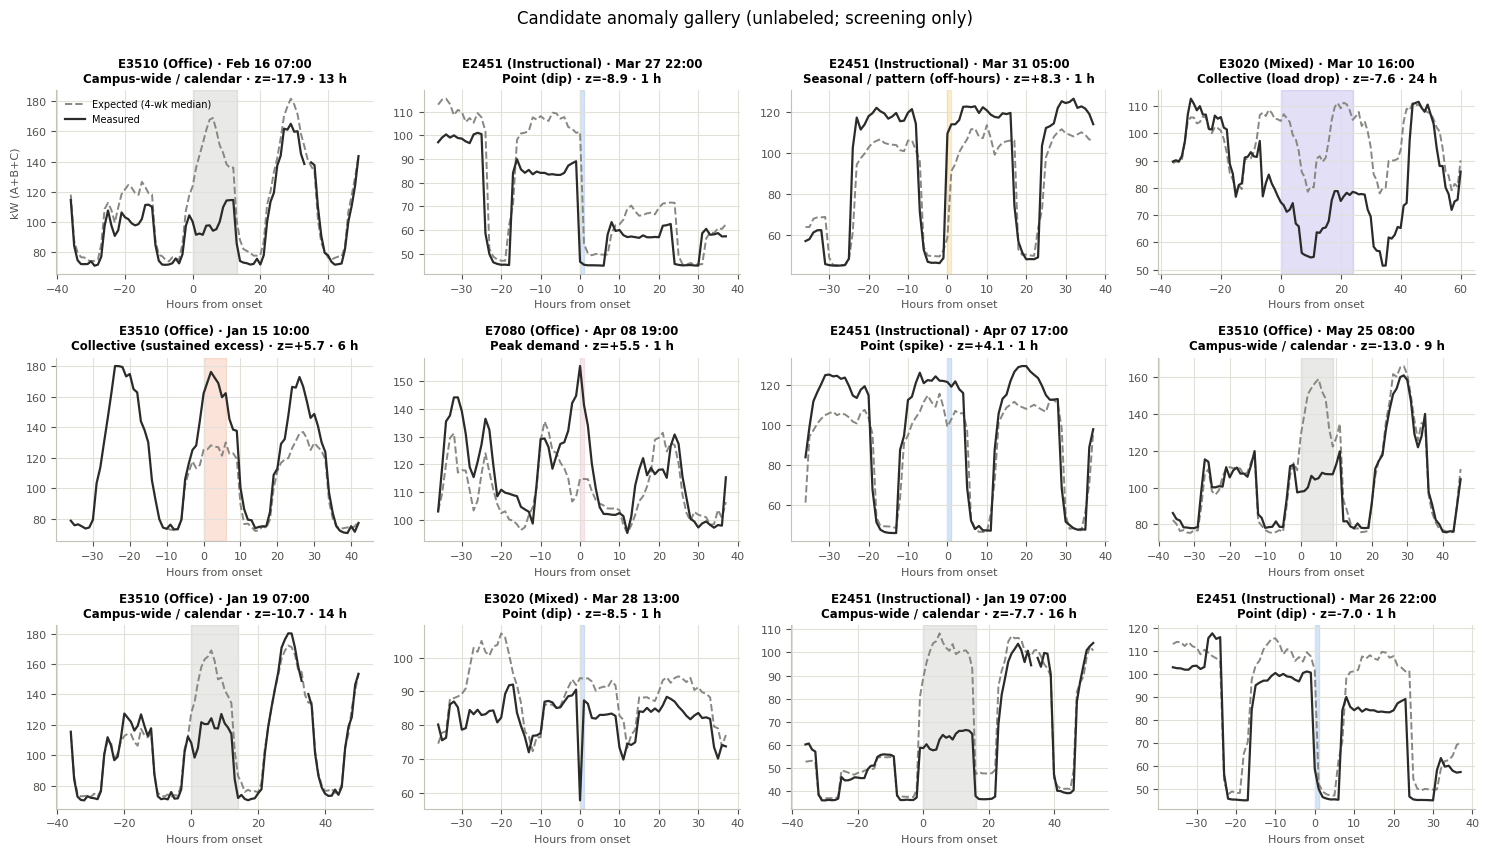

In [18]:
CAT_COLOR = {"Data integrity": "#008300", "Campus-wide / calendar": "#898781", "Peak demand": "#e87ba4",
             "Seasonal / pattern (off-hours)": "#eda100", "Point (spike)": "#2a78d6", "Point (dip)": "#2a78d6",
             "Collective (sustained excess)": "#eb6834", "Collective (load drop)": "#6250d6"}
# One example per category first, then the strongest remaining candidates
picks = cand.groupby("category").head(1)
picks = pd.concat([picks, cand.drop(picks.index)]).head(12)
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for ax, (_, r) in zip(axes.flat, picks.iterrows()):
    f = resid_store[r.meter]
    win = f.loc[r.start - pd.Timedelta(hours=36): r.end + pd.Timedelta(hours=36)]
    x = (win.index - r.start) / pd.Timedelta(hours=1)
    ax.plot(x, win.expected, color="#898781", ls="--", lw=1.4, label="Expected (4-wk median)")
    ax.plot(x, win.actual, color="#2b2b29", lw=1.6, label="Measured")
    ax.axvspan(0, r.hours, color=CAT_COLOR[r.category], alpha=0.18)
    ax.set_title(f"{r.meter} ({r.type}) · {r.start:%b %d %H:00}\n{r.category} · z={r.peak_z:+.1f} · {r.hours} h", fontsize=8.5)
    ax.set_xlabel("Hours from onset", fontsize=8)
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(picks):]:
    ax.axis("off")
axes[0, 0].set_ylabel("kW (A+B+C)", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Candidate anomaly gallery (unlabeled; screening only)", y=1.0, fontsize=12)
fig.tight_layout()
plt.show()

,median_excursion_kW,p99_excursion_kW,largest_excursion_kW,pct_bins_over_30pct_of_mean
meter,,,,
E2451,3.6,55.9,73.2,42.9
E3020,38.4,76.5,87.0,66.7
E3510,36.9,80.5,101.0,54.9
E7080,5.9,69.1,81.7,30.7
E7085,34.3,79.3,89.0,71.4


75 fifteen-minute bins exceed their own meter's 99.9th-percentile excursion


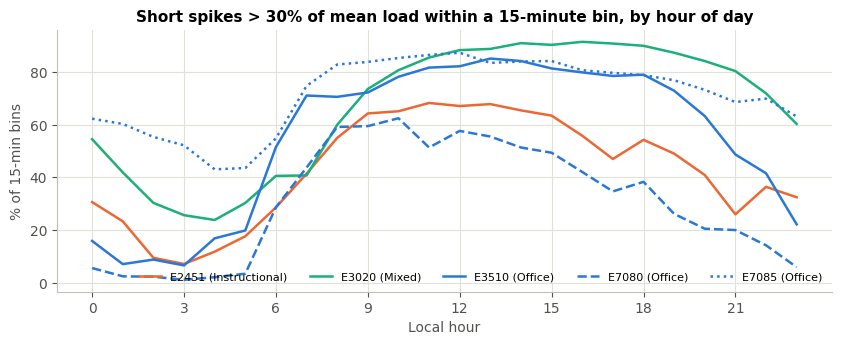

In [19]:
# Short spikes hidden by averaging: how far the 2-second maximum rises above the 15-minute mean
sp = agg15.dropna(subset=["kW", "kW_max"]).copy()
sp["excursion_kW"] = sp.kW_max - sp.kW
mean_load = hourly.groupby("meter").kW.mean()
sp["excursion_pct"] = 100 * sp.excursion_kW / sp.meter.map(mean_load)
spike_tab = sp.groupby("meter").agg(
    median_excursion_kW=("excursion_kW", "median"),
    p99_excursion_kW=("excursion_kW", lambda s: s.quantile(0.99)),
    largest_excursion_kW=("excursion_kW", "max"),
    pct_bins_over_30pct_of_mean=("excursion_pct", lambda s: 100 * (s > 30).mean())).reindex(METERS)
display(spike_tab.round(1))
thr = sp.groupby("meter").excursion_kW.quantile(0.999)
spikes = sp[sp.excursion_kW > sp.meter.map(thr)]
print(f"{len(spikes)} fifteen-minute bins exceed their own meter's 99.9th-percentile excursion")

fig, ax = plt.subplots(figsize=(10, 3.4))
sp["hour"] = sp.t_local.dt.hour
for m in METERS:
    share = sp[sp.meter == m].groupby("hour").excursion_pct.apply(lambda s: 100 * (s > 30).mean())
    ax.plot(share.index, share.values, **style(m))
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Local hour")
ax.set_ylabel("% of 15-min bins")
ax.set_title("Short spikes > 30% of mean load within a 15-minute bin, by hour of day")
ax.legend(fontsize=8, ncol=5)
plt.show()

In [20]:
# Data-integrity events: recording gaps and runs of identical (repeated) readings, grouped by time
gi = gaps.assign(kind="Missing readings (gap)", start=gaps.last_before_utc, secs=gaps.seconds)
fi = flats.groupby(["meter", "start_utc"]).seconds.max().reset_index().assign(kind="Repeated value (stuck)", start=lambda d: d.start_utc, secs=lambda d: d.seconds)
di = pd.concat([gi[["meter", "kind", "start", "secs"]], fi[["meter", "kind", "start", "secs"]]])
di["when"] = di.start.dt.floor("15min")
dtab = (di.groupby(["when", "kind"]).agg(meters=("meter", lambda s: ", ".join(sorted(set(s)))), n_meters=("meter", "nunique"),
                                         minutes=("secs", lambda s: round(s.max() / 60, 1))).reset_index())
dtab["local_time"] = dtab.when.dt.tz_convert(TZ).dt.strftime("%a %b %d %H:%M")
display(dtab[["local_time", "kind", "minutes", "n_meters", "meters"]])

,local_time,kind,minutes,n_meters,meters
0,Tue Jan 20 17:15,Missing readings (gap),19.6,5,"E2451, E3020, E3510, E7080, E7085"
1,Wed Feb 04 12:45,Missing readings (gap),0.9,2,"E7080, E7085"
2,Tue Feb 17 17:30,Missing readings (gap),20.0,5,"E2451, E3020, E3510, E7080, E7085"
3,Tue Feb 17 17:30,Repeated value (stuck),20.0,1,E3020
4,Tue Feb 24 03:00,Missing readings (gap),220.1,1,E2451
5,Tue Mar 17 17:15,Missing readings (gap),20.5,5,"E2451, E3020, E3510, E7080, E7085"
6,Tue Mar 17 17:15,Repeated value (stuck),20.5,5,"E2451, E3020, E3510, E7080, E7085"
7,Wed Mar 18 07:30,Missing readings (gap),0.9,5,"E2451, E3020, E3510, E7080, E7085"
8,Tue Apr 21 17:30,Missing readings (gap),21.2,5,"E2451, E3020, E3510, E7080, E7085"
9,Tue Apr 21 17:30,Repeated value (stuck),21.2,5,"E2451, E3020, E3510, E7080, E7085"


In [21]:
# Power-quality screen from the 15-minute min/max of Voltage A-N and frequency
pq = agg15.copy()
nominal = pq.groupby("meter").V_AN_mean.median()
pq["V_dip_%"] = 100 * (pq.V_AN_min / pq.meter.map(nominal) - 1)
print("Median Voltage A-N per meter (V):", nominal.round(1).to_dict(), "| 277 V nominal (480Y/277 V service)")
print(f"Lowest 15-min minimum voltage: {pq.V_AN_min.min():.1f} V ({(pq.V_AN_min.min()/277-1)*100:+.1f}% vs 277 V); "
      f"highest maximum: {pq.V_AN_max.max():.1f} V ({(pq.V_AN_max.max()/277-1)*100:+.1f}%)")
freq_ev = pq[pq.Freq_min < 59.9].groupby("bin_utc").meter.nunique()
print(f"Frequency below 59.90 Hz in {len(freq_ev)} fifteen-minute bins; seen at all 5 meters in {int((freq_ev == 5).sum())} of them "
      f"(lowest {pq.Freq_min.min():.3f} Hz)")
dips = pq[pq["V_dip_%"] <= -2.5].groupby("bin_utc").meter.nunique()
print(f"Voltage dips >= 2.5% below a meter's median: {len(dips)} bins; {int((dips >= 3).sum())} of them at >= 3 meters at once")

Median Voltage A-N per meter (V): {'E2451': 282.5, 'E3020': 282.8, 'E3510': 283.3, 'E7080': 280.9, 'E7085': 282.6} | 277 V nominal (480Y/277 V service)
Lowest 15-min minimum voltage: 271.9 V (-1.8% vs 277 V); highest maximum: 287.7 V (+3.9%)
Frequency below 59.90 Hz in 4 fifteen-minute bins; seen at all 5 meters in 3 of them (lowest 59.835 Hz)
Voltage dips >= 2.5% below a meter's median: 23 bins; 3 of them at >= 3 meters at once


In [22]:
cnt = cand.category.value_counts()
n_gap_events = gaps.assign(t=gaps.last_before_utc.dt.floor("10min")).t.nunique()
flat_events = flats.assign(t=flats.start_utc.dt.floor("10min")).t.nunique()
long_coll = cand[(cand.category.str.startswith("Collective")) & (cand.hours >= 12)]
taxonomy = pd.DataFrame([
    ("spike", "Point (spike) / 2-s spikes inside 15-min bins",
     f"{cnt.get('Point (spike)', 0)} hourly; 2-s peaks > 30% of mean load in "
     f"{spike_tab.pct_bins_over_30pct_of_mean.min():.0f}-{spike_tab.pct_bins_over_30pct_of_mean.max():.0f}% of 15-min bins at every meter (routine); "
     f"{len(spikes)} bins above each meter's own 99.9th pct"),
    ("dip", "Point (dip)", f"{cnt.get('Point (dip)', 0)}"),
    ("level_shift / trend_change", "Collective lasting >= 12 h", f"{len(long_coll)}"),
    ("overnight_load", "Seasonal / pattern (off-hours)", f"{cnt.get('Seasonal / pattern (off-hours)', 0)}"),
    ("seasonal_disruption / reversed / time_warp", "Shape changes", "Not separately screened (would need shape metrics)"),
    ("variance_burst", "Unusual 15-min variability", "Not separately screened"),
    ("dropout", "Recording gaps > 30 s", f"{len(gaps)} gaps, {n_gap_events} distinct times (mostly all meters together)"),
    ("stuck_sensor", "Identical readings >= 10 min", f"{len(flats)} channel-runs, {flat_events} distinct times (all phases, mostly all meters)"),
    ("peak demand", "Peak above previous 28 days' 99.5th pct", f"{cnt.get('Peak demand', 0)}"),
    ("hvac_contextual", "High load on a mild day", "Not assessable without weather data"),
    ("pv_underperformance", "Solar generation deficit", "Not applicable: no export (Quadrant II/III ~ 0) at any meter"),
], columns=["Synthetic kind (dashboard generator)", "Real-data screen", "Observed in Jan–May 2026"])
display(taxonomy)

,Synthetic kind (dashboard generator),Real-data screen,Observed in Jan–May 2026
0,spike,Point (spike) / 2-s spikes inside 15-min bins,1 hourly; 2-s peaks > 30% of mean load in 31-71% of 15-min bins at every meter (routine); 75 bins above each meter's own 99.9th pct
1,dip,Point (dip),24
2,level_shift / trend_change,Collective lasting >= 12 h,2
3,overnight_load,Seasonal / pattern (off-hours),35
4,seasonal_disruption / reversed / time_warp,Shape changes,Not separately screened (would need shape metrics)
5,variance_burst,Unusual 15-min variability,Not separately screened
6,dropout,Recording gaps > 30 s,"48 gaps, 11 distinct times (mostly all meters together)"
7,stuck_sensor,Identical readings >= 10 min,"36 channel-runs, 4 distinct times (all phases, mostly all meters)"
8,peak demand,Peak above previous 28 days' 99.5th pct,1
9,hvac_contextual,High load on a mild day,Not assessable without weather data


### Findings

- **91 candidate events** at the |z| ≥ 4 threshold. The largest are **federal holidays**: Presidents' Day, Memorial Day and MLK Day show as campus-wide drops of 40–75 kW. These are calendar effects, not faults, so the dashboard and detectors need a holiday and academic calendar to avoid flagging them.
- **Off-hours / overnight load is the most common building-specific candidate (35).** These appear at all five meters but are most frequent at E2451 (12) and E3020 (10). Examples include unusual 05:00 start-ups at E2451 on Mar 30–31, the strongest at +51 kW (z = +8.3).
- **Sustained load drops worth investigating:** E3020 (Mixed) ran 30 kW below expected for about 24 hours from Mar 10 and again on Mar 11–12 (about −1,200 kWh in total). Only that meter is affected and it isn't a holiday, so it's a good real "collective / load drop" example for the dashboard.
- **Late-March dips** at E2451, E3020 and E3510 (Mar 26–28) line up with the likely spring break. Encoding the academic calendar should explain them.
- **Peak demand above the recent normal peak is rare (1 event)**, as are hour-long spikes (1).
- **Short spikes are normal at the 2-second level.** At every meter, the 2-second peak exceeds the 15-minute average by more than 30% of mean load in 31–71% of bins. Spikes therefore can't be judged from hourly data: point anomalies need meter-specific thresholds applied at full resolution.
- **Data integrity has a clear pattern: a recurring outage of about 20 minutes on the third Tuesday of every month, around 17:15–17:45** (Jan 20, Feb 17, Mar 17, Apr 21, May 19), at all five meters at once. There was also one on Thu Apr 30 at 13:15.
  - **Recorded as repeated values:** in some months the outage shows up as **repeated identical values** rather than missing rows, so the dashboard must check for "stuck" values and not only gaps.
  - **Other gaps:** the only meter-specific problem is E2451's 3.7-hour gap on Feb 24.
- **Power quality is healthy:**
  - **Voltage:** line-to-neutral voltage stays within −1.8% to +3.9% of 277 V (480Y/277 V service), inside the ANSI C84.1 ±5% range.
  - **Frequency:** it dipped below 59.90 Hz three times at all five meters simultaneously, which points to grid-level events.
  - **Voltage dips:** three of 23 voltage dips (≥2.5% below a meter's median) were also campus-wide.
- **Compared with the synthetic generator (table above):**
  - **Present in real data:** dips, off-hours load, sustained drops, dropouts and stuck values, and holiday effects. The synthetic data treats holiday effects as normal.
  - **Rare:** peak-demand exceedances and hourly spikes.
  - **Not assessable without more data:** HVAC-on-a-mild-day (needs weather data) and shape distortions (need shape metrics).
  - **Not applicable:** PV underperformance, since these meters export no power.
  - **Suggested generator changes:** add holidays, the monthly logging outage and routine 2-second spikes as normal behaviour, and drop the PV scenarios for these meters.